---
---
## Trabajo Práctico 2 - Probabilidad Continua
---
---

Considerar 20 variables aleatorias que siguen una distribución normal estándar $(X_1, . . . , X_{20})$ y hacer el cambio de variables $Y_i = X^2_i$. Identificar que función de densidad de probabilidad siguen las nuevas variables $Y_i$. Construir una nueva variable aleatoria $Z=\sum^{20}_{i=1} Y_i$. A continuación simular las 20 variables $X_i$ y calcular el valor $Z$ correspondiente. Repetir este proceso 10.000 veces y hacer un histograma de frecuencias de $Z$. Comparar el histograma con una distribucion chi-cuadrado y otra normal con parametros apropiados.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm, chi2

In [ ]:
#Genero 20 valiables aleatorias Xi que siguen una distribución normal estandar
n_var = 20
X = norm.rvs(loc=0, scale=1, size=n_var, random_state=4)

#Cambio de variable

Y = X**2



### Cambio de variable
Sabiendo que la PDF de X es una normal estándar queremos averiguar cual será la distribución de $Y = g(X) = X^2$. Entonces, $X = g^{-1}(Y) = \sqrt{Y}$

$f_Y(y) =  f_X(x) \frac{1}{|{\frac{dg(X)}{dX}}|} = \frac{f_X(x)}{2X} = \frac{f_X(\sqrt{y})}{2\sqrt{Y}}$.

Donde $f_X(x) = \frac{1}{\sqrt{2\pi}}exp(\frac{x^2}{2})$.

Por lo tanto, $f_Y(y) = \frac{1}{\sqrt{2\pi y}}exp(\frac{y}{2})$ que se corresponde con una distribución $\chi^2$ con un grado de libertad.

In [ ]:
#Construyo la nueva variable Z

Z = np.sum(Y, axis=0)


### Simulación
En este punto quiero hacer 10mil simulaciones de 20 variables aleatorias $X_i$. Para eso, cambiaré el size agregandole el numero de simulaciones. Luego, construiré $Y_i$, elevando al cuadrado $X_i$. Por último construiré Z sumando los valores de $Y_i$ obteniendo 10mil valores de Z que seguirá una distribución $\chi^2$ con 20 grados de libertad.

In [ ]:
n_sims = 10000

X = norm.rvs(loc=0, scale=1, size=[n_var, n_sims], random_state=42)
Y = X**2
Z = np.sum(Y, axis=0)


#Momentos de Z
media = np.mean(Z)
var = np.var(Z)
std = np.sqrt(var)

print('Media =', media, '||', 'Varianza = ', var, '||', 'Desviación estándar = ', std)


Media = 19.996744080665643 || Varianza =  39.553631303645695 || Desviación estándar =  6.289167775123008


### Histograma de frecuencia, distribución $\chi^2$ y distribución normal
Realizaré un histograma de frecuencias para la variable Z y luego lo compararé con una distribución $\chi^2$ y con una distribución normal con parámetros adecuados. Ambas evaluadas en el rango $[0, \mu + 5\sigma]$.

##### Momentos de una distribución $\chi^2$
La media de una distribución $\chi^2$ coincide con los grados de libertad k, en este caso 20. Además, La varianza está dada por $2k$

-$\mu$_teo = 20

-var_teo = 40

-std_teo = 6.324




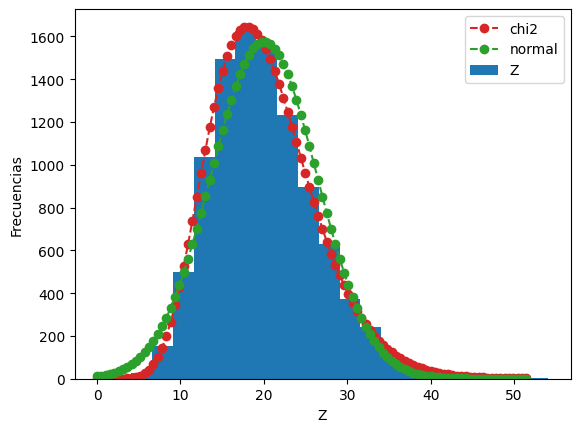

In [ ]:
#Histograma de frecuencia
n, bin_edges = np.histogram(Z, 20)
bin_width = bin_edges[1] - bin_edges[0]
scale_factor = bin_width*n_sims


#Distribuciones teoricas
x_min = 0
x_max = media + 5*std
x_eval = np.linspace(x_min, x_max, 100)
chi2_dist = chi2.pdf(x_eval, n_var, loc=0, scale=1)  #la media teórica coincide con n_var = 20
norm_dist = norm.pdf(x_eval, loc=20 , scale=np.sqrt(40))

#Gráficos
plt.plot(x_eval, scale_factor*chi2_dist, marker='o', linestyle= '--', color='tab:red', label='chi2')
plt.plot(x_eval, scale_factor*norm_dist, marker='o', linestyle= '--', color='tab:green', label='normal')
plt.hist(Z, 20, label = "Z")
plt.xlabel('Z')
plt.ylabel('Frecuencias')
plt.legend()
plt.show()


Se observa que la distribución $\chi^2$ con $k=20$ se ajusta mejor al histograma de frecuencias que la distribución normal.